In [144]:
# import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Data Analysis

In [107]:
# download cafe sales dataset from Kaggle
import kagglehub
path = kagglehub.dataset_download("ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training")
df_cafe = pd.read_csv(path + "/dirty_cafe_sales.csv")
df_cafe.head()

Using Colab cache for faster access to the 'cafe-sales-dirty-data-for-cleaning-training' dataset.


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [108]:
# display data shape
df_cafe.shape # <-- should return (10000, 8)

(10000, 8)

## Handling missing values
Unfortunately it is often the case that the datasets we have access to are not perfect and often times have missing values for some entries, and as such we won't be able to do much with the data without handling these missing values. It's important to investigate whether or not your data actually has missing values (often times reported as "Not a Number" or `NaN`) which we will do below for the `df_cafe` data.

In [109]:
# return number of missing values per column
df_cafe.isna().sum()

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


as we can see it turns out our dataset has a lot of missing values! So the first question one might have is "how do we handle this?" and it turns out there are multiple ways we could approach this. One such way is to simply remove any data entries that have missing values. Let's see this in action with the code cell below.

In [110]:
# Replace placeholders with missing values
df_cafe = df_cafe.replace(
    ["ERROR", "UNKNOWN"], pd.NA
)
# Examine missing values again
df_cafe.isna().sum()

,0
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


In [111]:
df_cafe_drop = df_cafe.dropna()
display(df_cafe_drop.isna().sum())
print(f"New shape after removing missing value columns is: {df_cafe_drop.shape}")

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


New shape after removing missing value columns is: (3089, 8)


Now our `df_cafe` has all the problematic missing values removed and we can work with the dataset. However, there are multiple concerns about simply haphazardly removing values from our dataset: 1) It can significantly reduce the size of our dataset (e.g. for `df_cafe` we threw out roughly $70\%$ of our data) which may leave us with insufficient amount data to make a meaningful model and 2)for time-series problems throwing out rows might mean we will have uneven number of time points in our dataset. These are two key problems amongst many others. So we introduce another way to handle missing values namely *data imputation* where we instead replace the missing values with some sensible value. Below is one such approach...

In [112]:
# Convert numeric columns to float so we can calculate their means
df_cafe['Quantity'] = pd.to_numeric(df_cafe['Quantity'], errors='coerce')
df_cafe['Price Per Unit'] = pd.to_numeric(df_cafe['Price Per Unit'], errors='coerce')
df_cafe['Total Spent'] = pd.to_numeric(df_cafe['Total Spent'], errors='coerce')

# Define fill values using corrected dtypes and columns
fill_values = {
    'Item': df_cafe['Item'].mode()[0],
    'Quantity': df_cafe['Quantity'].mean(),
    'Price Per Unit': df_cafe['Price Per Unit'].mean(),
    'Total Spent': df_cafe['Total Spent'].mean(),
    'Payment Method' : df_cafe['Payment Method'].mode()[0],
    'Location': df_cafe['Location'].mode()[0],
    'Transaction Date': df_cafe['Transaction Date'].mode()[0],
}

df_cafe_imputed = df_cafe.fillna(fill_values)
display(df_cafe_imputed.isna().sum())
print(f"Imputed dataframe shape: ", df_cafe_imputed.shape)

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


Imputed dataframe shape:  (10000, 8)


Here we have successfully saved all of our data and it is now usable. Of course, the actually quality of this imputation is variable and may not actually be good, and unfortunately as it turns out the type of imputation is very problem dependent so think about what you are modelling before modifying your data!

# Dataset
For this workshop we are going to analyze and investigate the Mauna Loa Atmospheric Carbon Dioxide Emission Dataset from the National Ocean and Atmospheric Administration (NOAA). The dataset contains $5$ columns (`year`, `month`, `day`, `decimal_year`, and `co2_ppm`). Our first step will be download the dataset into a `pandas` dataframe and investigate its shape and properties.

In [114]:
# Load Mauna Loa CO2 dataset as pandas dataframe
url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_daily_mlo.csv"
column_names = ['year', 'month', 'day', 'decimal_year', 'co2_ppm']

df = pd.read_csv(url, comment='#', names=column_names)

## Building a Model for Regression (NOAA Data)
Before trying to develop any models to explain our data, you should always analyze your dataset to get a sense of the potential features for your model, what is the distribution of those parameters, and what might need to be cleaned-up (e.g. missing values, outliers, normalization, etc.). Will do some of that evalution to start.

In [115]:
# output shape of our dataset
df.shape

(16017, 5)

`df.shape` returns `(# of rows, # of columns)` of a pandas dataframe, so

```
df.shape
(16017,5)
```
tells us that our dataset has $16017$ rows and $5$ columns, which we already knew.



In [116]:
# Investigate column data types
display(df.dtypes)

# display dataset info
display(df.describe())

,0
year,int64
month,int64
day,int64
decimal_year,float64
co2_ppm,float64


,year,month,day,decimal_year,co2_ppm
count,16017.000000,16017.000000,16017.000000,16017.000000,16017.000000
mean,2000.900855,6.473622,15.772055,2001.395511,375.149070
std,14.731913,3.483183,8.794932,14.730507,28.073783
min,1974.000000,1.000000,1.000000,1974.378100,326.060000
25%,1989.000000,3.000000,8.000000,1989.397300,352.750000
50%,2001.000000,6.000000,16.000000,2001.597300,371.770000
75%,2014.000000,10.000000,23.000000,2014.046600,397.770000
max,2026.000000,12.000000,31.000000,2026.824700,433.950000


`df.dtypes` returns a pandas series with the datatype of each column

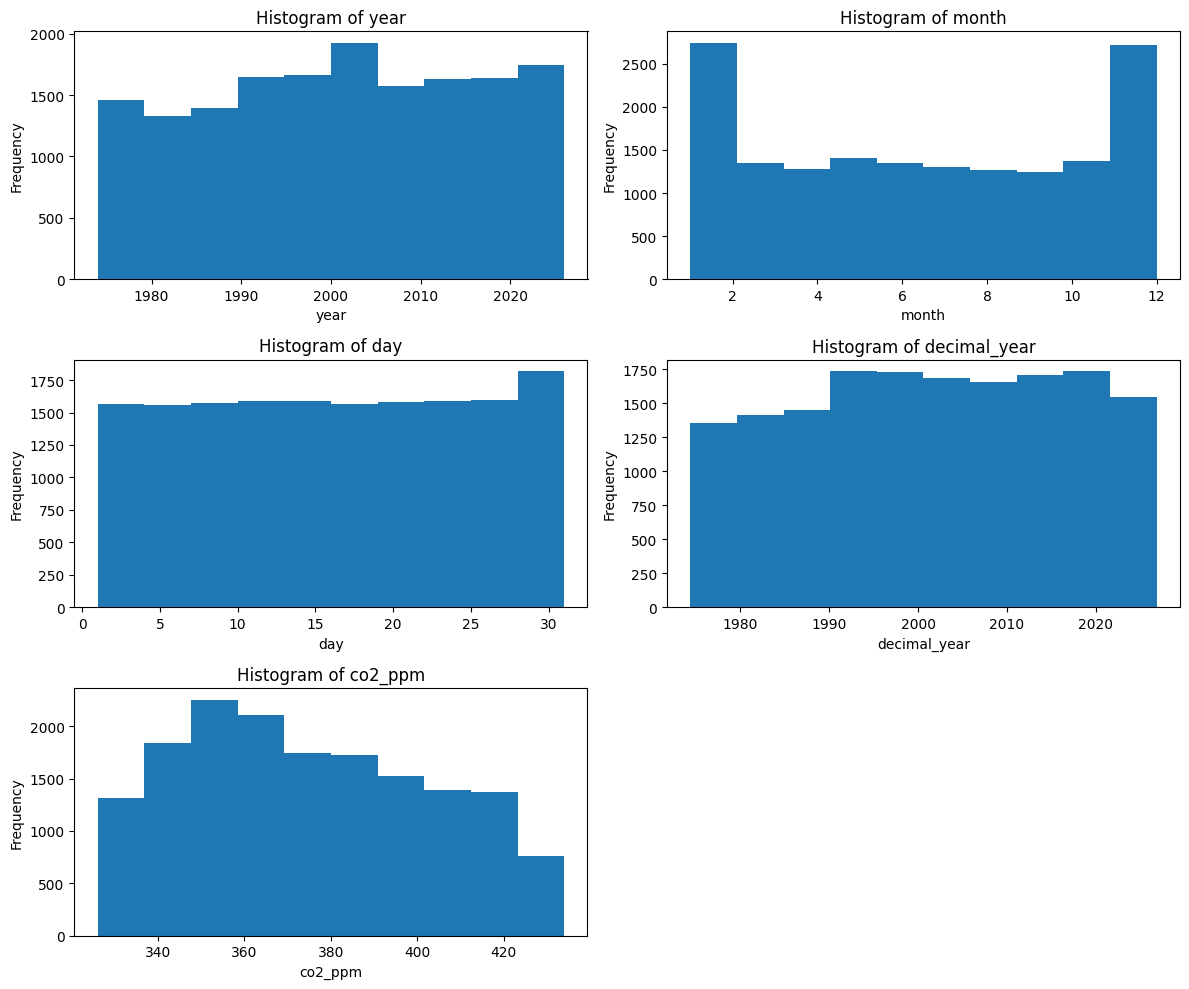

In [117]:
# Create a figure with a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Columns we want to plot
columns = ['year', 'month', 'day', 'decimal_year', 'co2_ppm']

# Plot each column on its respective subplot
for i, col in enumerate(columns):
    df.plot.hist(column=[col], ax=axes[i], legend=False)
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide the unused 6th subplot (index 5)
axes[5].axis('off')

# Adjust layout so labels don't overlap
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Mauna Loa CO2 Concentrations (Every 50th Daily Measurement)')

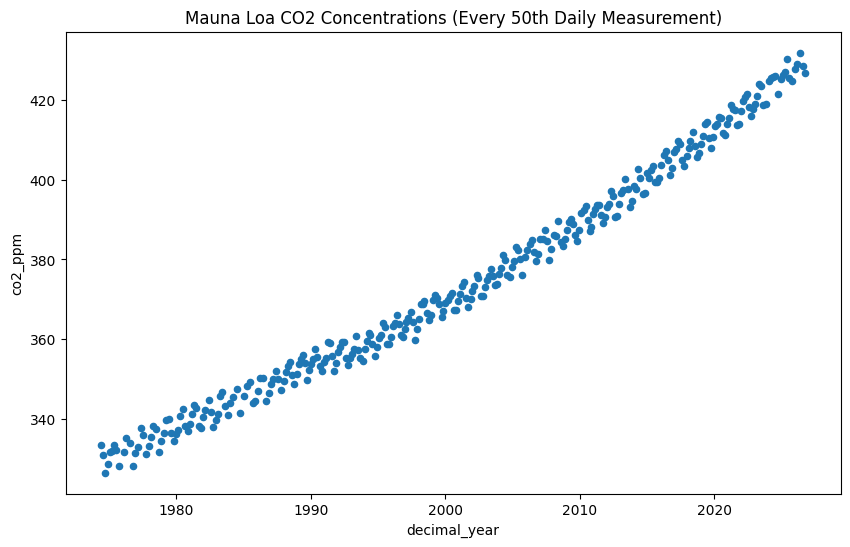

In [130]:
# Slice every 50th data point to make the plot less crowded
df_subset = df.iloc[::50]

# Plot the subset 'decimal_year' vs 'co2_ppm'
df_subset.plot.scatter(x='decimal_year', y='co2_ppm', figsize=(10, 6))
plt.title("Mauna Loa CO2 Concentrations (Every 50th Daily Measurement)")

## Linear Regression
From above it seems like `co2_ppm` has a linear relationship with `decimal_year`, and so a linear model might best describe the relationship, so let's use *linear regression*. For linear regression, as you can imagine as the name states, is the goal of fitting a linear model (a line) to a collection of data. That is we want to find $\beta, \beta_0$ such that
$$
  \beta, \beta_0  = \arg \min \sum_{i = 1}^N (\beta_0 + \beta * x_i - y_i)^2
$$
where $N$ is the number of data points. Thankfully, there exists many Python libraries such as `scikit-learn` that implement algorithms for finding such a $\beta, \beta_0$ for us, which we will demonstrate how to use below.

In [131]:
# Fit the linear model to the data
model = LinearRegression()
model.fit(df[['decimal_year']], df['co2_ppm'])

LinearRegression()

In [132]:
# output learned coeff
print(f"Learned coefficient: {model.coef_[0]}")
print(f"Learned intercept: {model.intercept_}")

Learned coefficient: 1.8884006725565001
Learned intercept: -3404.2875591225625


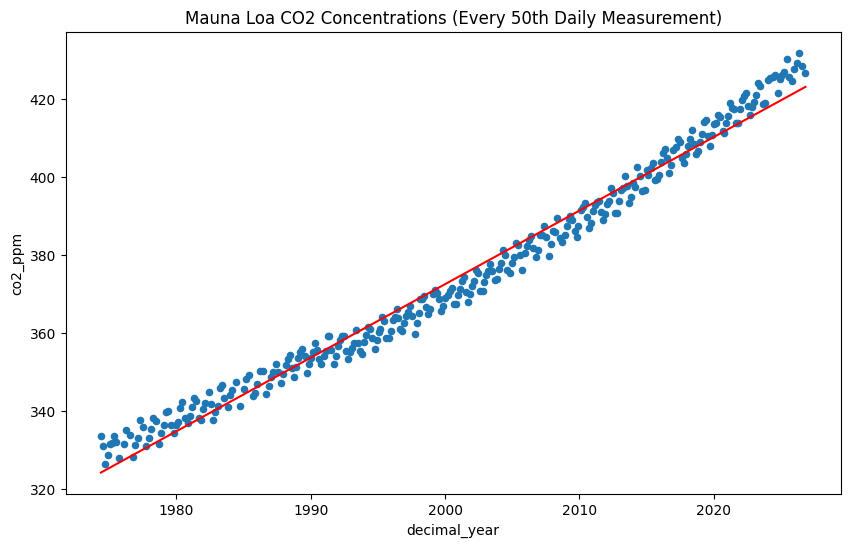

In [133]:
# plot model overlayed on original data
df_subset = df.iloc[::50]

# Plot the subset 'decimal_year' vs 'co2_ppm'
df_subset.plot.scatter(x='decimal_year', y='co2_ppm', figsize=(10, 6))
plt.title("Mauna Loa CO2 Concentrations (Every 50th Daily Measurement)")
plt.plot(df['decimal_year'], model.predict(df[['decimal_year']]), color='red')

It does seem like our linear model is a decent fit, but we can compute the actual error using scikit-learn's `mean_square_error`

In [123]:
lin_error = mean_squared_error(df['co2_ppm'], model.predict(df[['decimal_year']]))
print(f"Linear model error: {lin_error}")

Linear model error: 14.345450942281179


In [134]:
poly_feat = PolynomialFeatures(degree=2)
X_poly = poly_feat.fit_transform(df[['decimal_year']])
poly_model = LinearRegression()
poly_model.fit(X_poly, df['co2_ppm'])

LinearRegression()

In [138]:
# return deg-2 coeff.
print(f"Learned coefficients: {poly_model.coef_}")
print(f"Learned intercept: {poly_model.intercept_}")

Learned coefficients: [ 0.00000000e+00 -5.65722445e+01  1.46087825e-02]
Learned intercept: 55078.7104298709


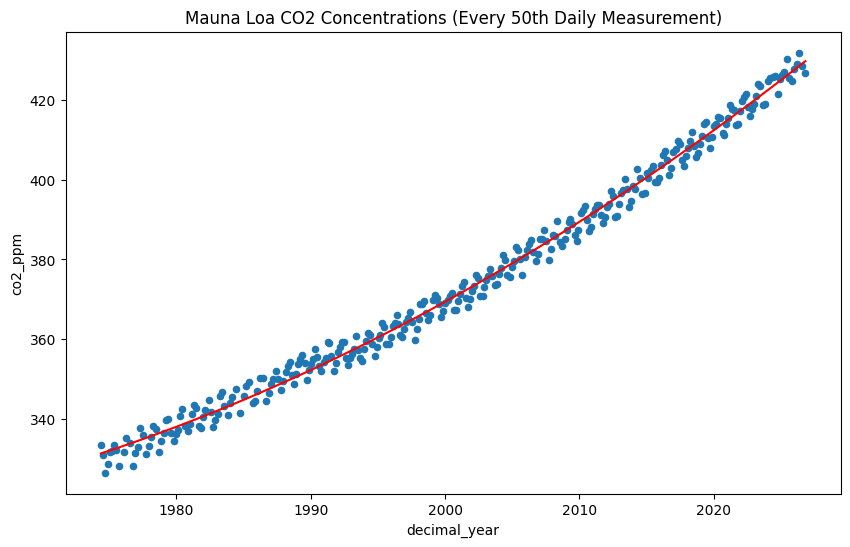

In [135]:
#plot degree 2 polynomial
df_subset = df.iloc[::50]

# Plot the subset 'decimal_year' vs 'co2_ppm'
df_subset.plot.scatter(x='decimal_year', y='co2_ppm', figsize=(10, 6))
plt.title("Mauna Loa CO2 Concentrations (Every 50th Daily Measurement)")
plt.plot(df['decimal_year'], poly_model.predict(X_poly), color='red')

Now let's take a look at our degree 2 polynomial fit MSE:

In [136]:
poly_error = mean_squared_error(df['co2_ppm'], poly_model.predict(X_poly))
print(f"Degree 2 polynomial model error: {poly_error}")

Degree 2 polynomial model error: 5.720016468531211


So it seems our degree 2 polynomial has a lower MSE than our linear model, which implies that it is a better fit. This is clear from the plot above. Now what might you think happens if we increase the degree of our polynomial?

In [170]:
# Scale the year feature BEFORE generating polynomial features to prevent numerical overflow
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['decimal_year']])

high_deg_poly_feat = PolynomialFeatures(degree=50)  # 50 degree polynomial!!
X_high_deg_poly = high_deg_poly_feat.fit_transform(X_scaled)

high_deg_poly_model = LinearRegression()
high_deg_poly_model.fit(X_high_deg_poly, df['co2_ppm'])

LinearRegression()

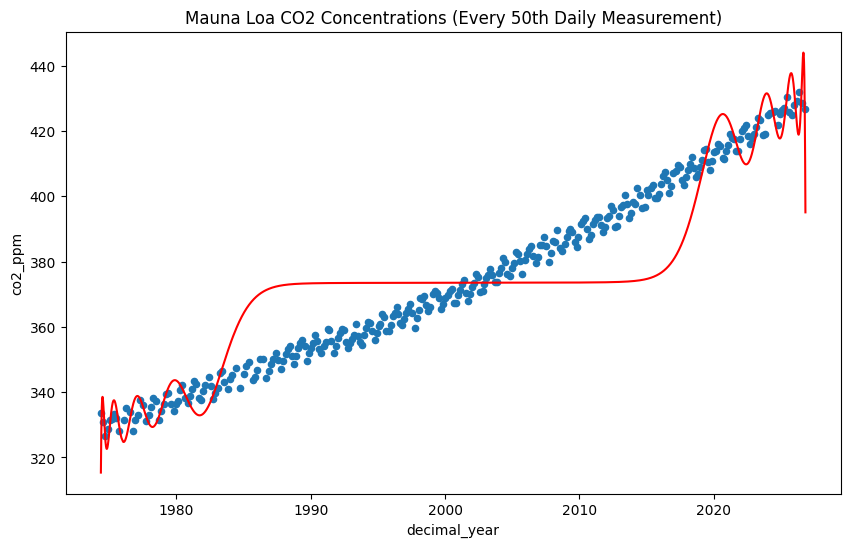

In [171]:
# plot poly overlayed data
df_subset = df.iloc[::50]

# Plot the subset 'decimal_year' vs 'co2_ppm'
df_subset.plot.scatter(x='decimal_year', y='co2_ppm', figsize=(10, 6))
plt.title("Mauna Loa CO2 Concentrations (Every 50th Daily Measurement)")
plt.plot(df['decimal_year'], high_deg_poly_model.predict(X_high_deg_poly), color='red')
plt.show()

In [169]:
high_deg_poly_error = mean_squared_error(df['co2_ppm'], high_deg_poly_model.predict(X_high_deg_poly))
print(f"Degree 45 polynomial model error: {high_deg_poly_error}")

Degree 45 polynomial model error: 193.93278191259992


# Linear Programming

# Classification

# References
1. *Dr. Xin Lan, NOAA/GML (gml.noaa.gov/ccgg/trends/) and Dr. Ralph Keeling, Scripps Institution of Oceanography (scrippsco2.ucsd.edu/).*

